In [1]:
import pandas as pd
import numpy as np
from typing import Optional
from pathlib import Path
import logging
import plotly.express as px
import itertools

logger = logging.getLogger(__name__)

In [2]:
# sample config
data_config = { 
    "minimal": False,
    "folder": "/Users/henrykraessig/code/bdb2025/data/", 
    "targetfolder": "./data", 
    "mask": 0.15, 
    "train": 0.7, 
    "val": 0.15, 
    "test": 0.15, 
    "interp": 40,
    "premask": True
}

In [3]:

# Base data loading functions
def load_csv_data(
    paths: list[Path]
) -> list[pd.DataFrame]:
    # TODO: look into reading from template, i.e. tracking_week_*.csv
    return [pd.read_csv(path) for path in paths]


def load_tracking_data(
    weeks: Optional[int | list[int]]=None,
    folder: Optional[Path]=None,
) -> pd.DataFrame:
   
    MIN_WEEK = 1
    MAX_WEEK = 9

    if not weeks:
        # defualt to all data
        weeks = range(MIN_WEEK, MAX_WEEK + 1)
    
    if isinstance(weeks, int):
        weeks = [weeks]
    weeks = set(weeks)
    
    for week in weeks:
        assert isinstance(week, int) and week >= MIN_WEEK and week <= MAX_WEEK, \
        f"provide integer weeks between {MIN_WEEK} and {MAX_WEEK}"

    print(f"reading data from weeks: {weeks}")

    # load data from a folderectory
    if folder and folder.exists():
        logger.info(f"reading tracking from {folder}")
        paths = [Path(folder, f'tracking_week_{n}.csv') for n in weeks]

        dfs = load_csv_data(paths)
        return pd.concat(dfs)
    
    raise FileNotFoundError


def load_player_data(
    folder: Optional[Path]=None,
) -> pd.DataFrame:

    if folder and folder.exists():
        logger.info(f"reading player data from {folder}")
        path = Path(folder, 'players.csv')

        return pd.read_csv(path)
    

def load_play_data(
        folder: Optional[Path]=None,
) -> pd.DataFrame:
    

    if folder and folder.exists():
        logger.info(f"reading play data from {folder}")
        path = Path(folder, 'plays.csv')

    return pd.read_csv(path)


def load_player_play_data(
        folder: Optional[Path]=None,
) -> pd.DataFrame:
    

    if folder and folder.exists():
        logger.info(f"reading play data from {folder}")
        path = Path(folder, 'player_play.csv')

    return pd.read_csv(path)


In [4]:
# simple graphing utility for troubleshooting
def debug_plot(tracking_df: pd.DataFrame):
    # collect one play
    gameid = tracking_df['gameId'].iat[0]
    playid = tracking_df['playId'].iat[0]

    df = tracking_df.loc[(tracking_df['gameId'] == gameid) & (tracking_df['playId'] == playid)]

    fig = px.scatter(
        df,
        x="x",
        y="y",
        animation_frame="frameId",
        title=f"test"
    )


    return fig

In [4]:
if data_config['minimal']: 
    tracking = load_csv_data([Path("minimal_tracking.csv")])[0]
else: 
    tracking = load_tracking_data(folder=Path(data_config["folder"]))
players = load_player_data(Path(data_config['folder']))
plays = load_play_data(Path(data_config["folder"]))
player_plays = load_player_play_data(Path(data_config["folder"]))

reading data from weeks: {1, 2, 3, 4, 5, 6, 7, 8, 9}


In [5]:
tracking.loc[(tracking['playId'] == 56) & (tracking['gameId'] == 2022090800)]

,gameId,playId,nflId,displayName,frameId,frameType,time,jerseyNumber,club,playDirection,x,y,s,a,dis,o,dir,event
6686928,2022090800,56,35472.0,Rodger Saffold,1,BEFORE_SNAP,2022-09-09 00:23:48.2,76.0,BUF,left,89.480000,29.520000,0.68,1.17,0.07,308.30,266.54,huddle_break_offense
6686929,2022090800,56,35472.0,Rodger Saffold,2,BEFORE_SNAP,2022-09-09 00:23:48.3,76.0,BUF,left,89.390000,29.510000,0.90,1.33,0.09,301.21,268.31,NaN
6686930,2022090800,56,35472.0,Rodger Saffold,3,BEFORE_SNAP,2022-09-09 00:23:48.4,76.0,BUF,left,89.280000,29.520000,1.13,1.29,0.11,294.13,271.96,NaN
6686931,2022090800,56,35472.0,Rodger Saffold,4,BEFORE_SNAP,2022-09-09 00:23:48.5,76.0,BUF,left,89.150000,29.520000,1.26,0.96,0.12,293.23,271.65,NaN
6686932,2022090800,56,35472.0,Rodger Saffold,5,BEFORE_SNAP,2022-09-09 00:23:48.6,76.0,BUF,left,89.000000,29.510000,1.47,0.88,0.15,271.60,269.37,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6691339,2022090800,56,NaN,football,188,AFTER_SNAP,2022-09-09 00:24:06.9,NaN,football,left,78.160004,36.650002,0.07,0.27,0.01,NaN,NaN,tackle
6691340,2022090800,56,NaN,football,189,AFTER_SNAP,2022-09-09 00:24:07,NaN,football,left,78.230003,36.389999,0.05,0.18,0.27,NaN,NaN,NaN
6691341,2022090800,56,NaN,football,190,AFTER_SNAP,2022-09-09 00:24:07.1,NaN,football,left,78.230003,36.389999,0.04,0.13,0.00,NaN,NaN,NaN
6691342,2022090800,56,NaN,football,191,AFTER_SNAP,2022-09-09 00:24:07.2,NaN,football,left,78.220001,36.389999,0.02,0.09,0.00,NaN,NaN,NaN


In [6]:
plays.loc[(plays['playId'] == 56) & (plays['gameId'] == 2022090800)]

,gameId,playId,playDescription,quarter,down,yardsToGo,possessionTeam,defensiveTeam,yardlineSide,yardlineNumber,...,yardsGained,homeTeamWinProbabilityAdded,visitorTeamWinProbilityAdded,expectedPointsAdded,isDropback,pff_runConceptPrimary,pff_runConceptSecondary,pff_runPassOption,pff_passCoverage,pff_manZone
13368,2022090800,56,(15:00) (Shotgun) J.Allen pass short right to ...,1,1,10,BUF,LA,BUF,25,...,6,-0.000031,0.000031,0.00442,True,NaN,NaN,0,Cover 6-Left,Zone


In [ ]:
### PRUNE COLUMNS

def prune_columns(tracking_df: pd.DataFrame, player_play_df: pd.DataFrame, play_df: pd.DataFrame, player_df: pd.DataFrame):
    
    id_cols = ['gameId', 'playId', 'nflId', 'frameId']

In [6]:
# perform easy filters on the data

def filter_pass_plays(): 
    ...
    

In [7]:
### SIMPLE CLEANING

def clean_tracking_angles(tracking_df: pd.DataFrame) -> pd.DataFrame: 
    logger.info("cleaning tracking data angles")
    # angles to radians
    tracking_df['o'] = ((-1 * tracking_df['o'] + 90) % 360) * np.pi / 180
    tracking_df['dir'] = ((-1 * tracking_df['dir'] + 90) % 360) * np.pi / 180

    return tracking_df


def standardize_tracking_plays(tracking_df: pd.DataFrame) -> pd.DataFrame: 
    logger.info("standardizing tracking data")
    # standardize locations to the ball snap location
    ball = (
        tracking_df
        .loc[
            (tracking_df['event'] == 'ball_snap') & 
            (tracking_df['club'] == 'football'),
            
            ['gameId', 'playId', 'frameId', 'x', 'y']
        ]
    )
    tracking_df = tracking_df.merge(
        ball, # ball info for starting time
        how='left', 
        on=('gameId', 'playId'),
        suffixes=('', '_ball_snap')
    )

    tracking_df['x'] = tracking_df['x'] - tracking_df['x_ball_snap']
    tracking_df['y'] = tracking_df['y'] - tracking_df['y_ball_snap']

    # normalize play directions to the right
    tracking_df['x'] = ((tracking_df['playDirection'] == 'left') * -2 + 1) * tracking_df['x']
    tracking_df['o'] = ( ((tracking_df['playDirection'] == 'left') * np.pi) + tracking_df['o'] ) % (2 * np.pi) 
    tracking_df['dir'] = ( ((tracking_df['playDirection'] == 'left') * np.pi) + tracking_df['dir'] ) % (2 * np.pi) 

    # x and y components of orientation and velocity
    tracking_df['ox'] = np.cos(tracking_df['o'])
    tracking_df['oy'] = np.sin(tracking_df['o'])

    tracking_df['vx'] = np.cos(tracking_df['dir']) * tracking_df['s']
    tracking_df['vy'] = np.sin(tracking_df['dir']) * tracking_df['s']

    tracking_df['nflId'] = tracking_df['nflId'].fillna(-1) # football

    return tracking_df


def clean_player_data(player_df: pd.DataFrame) -> pd.DataFrame:
    logger.info("cleaning player data")
    
    # clean height
    feet = pd.to_numeric(player_df['height'].str.split('-', expand=True)[0])
    inches = pd.to_numeric(player_df['height'].str.split('-', expand=True)[1])
    player_df['height_inches'] = 12 * feet + inches

    # create zscore for height
    player_df['height_z'] = (player_df['height_inches'] - player_df['height_inches'].mean()) / player_df['height_inches'].std()
    player_df['weight_z'] = (player_df['weight'] - player_df['weight'].mean()) / player_df['weight'].std()

    return player_df


def football_relative_positions(tracking_df: pd.DataFrame) -> pd.DataFrame: 
    ball = (
        tracking_df
        .loc[
            (tracking_df['club'] == 'football'),
            ['gameId', 'playId', 'frameId', 'x', 'y']
        ]
    )

    tracking_df = tracking_df.merge(
        ball, 
        how='left', 
        on=('gameId', 'playId', 'frameId'), 
        suffixes=('', '_ball')
    )

    tracking_df['dis_to_ball'] = np.sqrt(
        (tracking_df['x'] - tracking_df['x_ball'])**2 + (tracking_df['y'] - tracking_df['y_ball'])**2
    )

    return tracking_df


In [ ]:
tracking = clean_tracking_angles(tracking)
tracking = standardize_tracking_plays(tracking)
# tracking = football_relative_positions(tracking)


players = clean_player_data(players)


In [9]:
### FILTERING

from scipy.interpolate import CubicSpline

def filter_play_start_frames(tracking_df: pd.DataFrame) -> pd.DataFrame:
    # standardize frameId to 0 at snap & remove presnap frames
    tracking_df['frameId'] = tracking_df['frameId'] - tracking_df['frameId_ball_snap']
    return tracking_df.loc[tracking_df['frameId'] >=  0]


def filter_play_end_frames(tracking_df: pd.DataFrame) -> pd.DataFrame: 
    # create a stop point variable to track frames after the play
    tracking_df['stop_point'] = pd.NA
    tracking_df.loc[tracking_df['event'].isin(['pass_outcome_incomplete', 'qb_sack', 'tackle']), 'stop_point'] = True 
    # fill stopping points forward to filter out moments after a defined route stop
    tracking_df['stop_point'] = tracking_df.groupby(['gameId', 'playId', 'nflId'])['stop_point'].ffill()

    return tracking_df.loc[tracking_df['stop_point'].isna()].drop(columns='stop_point') # remove redundant column


def filter_route_end_frames(tracking_df: pd.DataFrame) -> pd.DataFrame: 
    # potentially complex logic to find when a route runner's designed route has ended
    ...


def filter_football_tracking_frames(tracking_df: pd.DataFrame) -> pd.DataFrame: 
    return tracking_df.loc[tracking_df['club'] != 'football']



In [ ]:
tracking = filter_play_start_frames(tracking)
tracking = filter_play_end_frames(tracking)
# tracking = filter_football_tracking_frames(tracking)

In [11]:
routes_per_play = tracking.groupby(['gameId', 'playId'])['nflId'].nunique(dropna=False).iloc[0]
assert (tracking.groupby(['gameId', 'playId'])['nflId'].nunique(dropna=False) == routes_per_play).all()

routes_per_play

np.int64(23)

In [ ]:
### TRANSFORMS

# perform unique data transforms
def find_play_invariant_columns(play_df: pd.DataFrame, tracking_df: pd.DataFrame) -> tuple[pd.DataFrame, pd.DataFrame]: 
    # grab the column names for columns in the tracking data that won't change over the course of a given play
    cols_static = (tracking_df.groupby(['gameId', 'playId']).nunique() == 1).all(axis=0) # series w/ index colname and boolean value
    invariant_columns = cols_static.index[cols_static].tolist()

    tracking_invariant = tracking_df.groupby(['gameId', 'playId'])[invariant_columns].first()

    # tack them on to the plays dataframe
    play_df = play_df.merge(
        tracking_invariant,
        how='left', 
        on=('gameId', 'playId'),
    )    

    # remove them from the tracking dataframe
    return play_df, tracking_df.drop(columns=invariant_columns)


def find_player_play_invariant_columns(player_play_df: pd.DataFrame, tracking_df: pd.DataFrame) -> tuple[pd.DataFrame, pd.DataFrame]: 
    # grab the column names for columns in the tracking data that won't change over the course of a given play for a given player
    cols_static = (tracking_df.groupby(['gameId', 'playId', 'nflId']).nunique() == 1).all(axis=0) # series w/ index colname and boolean value
    invariant_columns = cols_static.index[cols_static].tolist()

    tracking_invariant = tracking_df.groupby(['gameId', 'playId', 'nflId'])[invariant_columns].first()


    # tack them on to the plays dataframe
    player_play_df = player_play_df.merge(
        tracking_invariant,
        how='left', 
        on=('gameId', 'playId', 'nflId'),
    )    

    # remove them from the tracking dataframe
    return player_play_df, tracking_df.drop(columns=invariant_columns)


def clean_player_play_data(player_play_df: pd.DataFrame, play_df: pd.DataFrame) -> tuple[pd.DataFrame, pd.DataFrame]: 

    player_play_df['is_ball'] = (player_play_df['club'] == 'football')

    merged = player_play_df[['gameId', 'playId', 'club']].copy().merge(play_df[['gameId', 'playId', 'possessionTeam', 'defensiveTeam']].copy(), how='left', on=('gameId', 'playId'))

    player_play_df['offense'] = (merged['club'] == merged['possessionTeam'])
    player_play_df['defense'] = (merged['club'] == merged['defensiveTeam'])

    return player_play_df, play_df


def interpolate_tracking_frames(tracking_df: pd.DataFrame, interp_frames: int=40) -> pd.DataFrame: 

    play_index = tracking_df.set_index(['gameId', 'playId']).sort_index()

    num_obs = interp_frames
    interpolated_columns = ['x', 'y', 'ox', 'oy', 'vx', 'vy', 'a']
    ids = play_index.index.unique()
    num_plays = len(ids)
    routes_per_play = tracking_df.groupby(['gameId', 'playId'])['nflId'].nunique(dropna=True).max()
    id_cols = ['gameId', 'playId', 'nflId', 'frameId']

    print(f"interpolating {len(interpolated_columns)} columns of data")
    print(f"columns: {interpolated_columns}")
    # array for interpolated movement
    movement_arr = np.zeros( (num_plays, routes_per_play, num_obs, len(interpolated_columns)), dtype=np.float32)
    nfl_ids = np.empty( (num_plays, routes_per_play), dtype=np.float32 )

    for i, (gameid, playid) in enumerate(ids): 
        
        play: pd.DataFrame = play_index.loc[gameid, playid]
        
        for ii, nflid in enumerate(play['nflId'].dropna().unique()):

            player: pd.DataFrame = play.loc[play['nflId'] == nflid]
            min_frame = player['frameId'].min()
            frame_range = player['frameId'].max() - min_frame
            t = np.array((player['frameId'] - min_frame) / frame_range)

            player_data = np.array(player[interpolated_columns])

            # smooth the info about the player over time
            spline = CubicSpline(t, player_data, axis=0, extrapolate=False)

            # take n observations
            observation_times = np.arange(num_obs) / num_obs

            # populate an array with smoothed values
            movement_arr[i, ii, ...] = spline(observation_times)
            nfl_ids[i, ii] = nflid



    # create new tracking dataframe
    tracking_df_data = movement_arr.reshape((-1, len(interpolated_columns)))
    id_arr = np.stack([
        np.repeat(ids.get_level_values(0), num_obs * routes_per_play),
        np.repeat(ids.get_level_values(1), num_obs * routes_per_play),
        nfl_ids.flatten().repeat(num_obs),
        np.tile(np.arange(num_obs), routes_per_play * num_plays)
    ], axis=-1)


    tracking_df = pd.DataFrame(
        data = np.concat([id_arr, tracking_df_data], axis=-1), 
        columns=id_cols + interpolated_columns
    )

    return tracking_df


def player_relative_positions(tracking_df: pd.DataFrame, player_play_df: pd.DataFrame):
    """For each player/play, make the player's position relative to their previous frame,
    and add start postions for each player/play
    """
    
    starts = (
        tracking_df
        .groupby(['gameId', 'playId', 'nflId'])
        [['x', 'y']]
        .first()
        .rename(columns={'x': 'x_start', 'y': 'y_start'})
    )


    tracking_df[['x', 'y']] = tracking_df.groupby(['gameId', 'playId', 'nflId'])[['x', 'y']].transform(lambda x: x - x.iloc[0])



    # join starts with player_play_df
    player_play_df = player_play_df.merge(
        starts, 
        how='left', 
        on=('gameId', 'playId', 'nflId')
    )

    return tracking_df, player_play_df



In [13]:
plays, tracking = find_play_invariant_columns(plays, tracking)
player_plays, tracking = find_player_play_invariant_columns(player_plays, tracking)
player_plays, plays = clean_player_play_data(player_plays, plays)
# tracking, player_plays = player_relative_positions(tracking, player_plays)

In [14]:
# tracking = interpolate_tracking_frames(tracking)

In [14]:
# mirror tracking data
# TODO: fix mirror starts when relative positions are used
def mirror_tracking_data(tracking_df: pd.DataFrame, player_play_df: pd.DataFrame, play_df: pd.DataFrame) -> pd.DataFrame:
    logger.info("mirroring tracking data")
    mirrored_tracking = tracking_df.copy()
    mirrored_starts = player_play_df.copy()
    mirrored_snaps = play_df.copy()

    mirrored_tracking['y'] = mirrored_tracking['y'] * -1
    mirrored_tracking['vy'] = mirrored_tracking['vy'] * -1
    mirrored_tracking['oy'] = mirrored_tracking['oy'] * -1
    mirrored_tracking['mirrored'] = True
    tracking_df['mirrored'] = False

    if 'y_start' in player_play_df.columns:
        mirrored_starts['y_start'] = mirrored_starts['y_start'] * -1
    mirrored_starts['mirrored'] = True
    player_play_df['mirrored'] = False

    mirrored_snaps['y_ball_snap'] = mirrored_snaps['y_ball_snap'] * -1
    mirrored_snaps['mirrored'] = True
    play_df['mirrored'] = False


    return pd.concat([tracking_df, mirrored_tracking]), pd.concat([player_play_df, mirrored_starts]), pd.concat([play_df, mirrored_snaps])


In [15]:
tracking, player_plays, plays = mirror_tracking_data(tracking, player_plays, plays)

count    97.000000
mean     49.206186
std      13.921610
min      21.000000
25%      40.000000
50%      48.000000
75%      57.000000
max      98.000000
Name: frameId, dtype: float64


<Axes: >

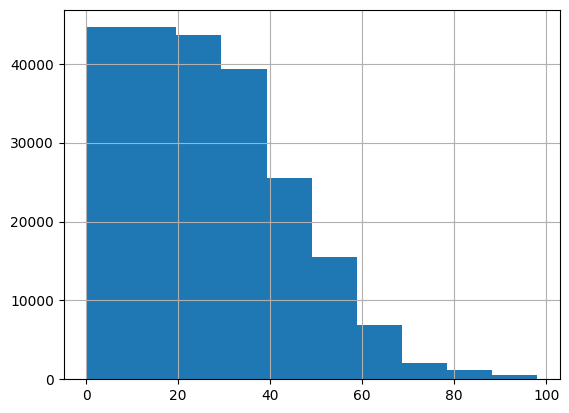

In [16]:
print(tracking.groupby(['gameId', 'playId'])['frameId'].max().describe())
tracking['frameId'].hist()

In [18]:
tracking.columns

Index(['gameId', 'playId', 'nflId', 'frameId', 'frameType', 'time',
       'jerseyNumber', 'x', 'y', 's', 'a', 'dis', 'o', 'dir', 'event', 'ox',
       'oy', 'vx', 'vy', 'x_ball', 'y_ball', 'dis_to_ball', 'mirrored'],
      dtype='object')

In [20]:
players.columns

Index(['nflId', 'height', 'weight', 'birthDate', 'collegeName', 'position',
       'displayName', 'height_inches', 'height_z', 'weight_z'],
      dtype='object')

In [21]:
player_plays.columns

Index(['gameId', 'playId', 'nflId', 'teamAbbr', 'hadRushAttempt',
       'rushingYards', 'hadDropback', 'passingYards', 'sackYardsAsOffense',
       'hadPassReception', 'receivingYards', 'wasTargettedReceiver',
       'yardageGainedAfterTheCatch', 'fumbles', 'fumbleLost',
       'fumbleOutOfBounds', 'assistedTackle', 'forcedFumbleAsDefense',
       'halfSackYardsAsDefense', 'passDefensed', 'quarterbackHit',
       'sackYardsAsDefense', 'safetyAsDefense', 'soloTackle', 'tackleAssist',
       'tackleForALoss', 'tackleForALossYardage', 'hadInterception',
       'interceptionYards', 'fumbleRecoveries', 'fumbleRecoveryYards',
       'penaltyYards', 'penaltyNames', 'wasInitialPassRusher',
       'causedPressure', 'timeToPressureAsPassRusher',
       'getOffTimeAsPassRusher', 'inMotionAtBallSnap', 'shiftSinceLineset',
       'motionSinceLineset', 'wasRunningRoute', 'routeRan',
       'blockedPlayerNFLId1', 'blockedPlayerNFLId2', 'blockedPlayerNFLId3',
       'pressureAllowedAsBlocker', 'timeT

In [22]:
plays.columns

Index(['gameId', 'playId', 'playDescription', 'quarter', 'down', 'yardsToGo',
       'possessionTeam', 'defensiveTeam', 'yardlineSide', 'yardlineNumber',
       'gameClock', 'preSnapHomeScore', 'preSnapVisitorScore',
       'playNullifiedByPenalty', 'absoluteYardlineNumber',
       'preSnapHomeTeamWinProbability', 'preSnapVisitorTeamWinProbability',
       'expectedPoints', 'offenseFormation', 'receiverAlignment',
       'playClockAtSnap', 'passResult', 'passLength', 'targetX', 'targetY',
       'playAction', 'dropbackType', 'dropbackDistance', 'passLocationType',
       'timeToThrow', 'timeInTackleBox', 'timeToSack', 'passTippedAtLine',
       'unblockedPressure', 'qbSpike', 'qbKneel', 'qbSneak',
       'rushLocationType', 'penaltyYards', 'prePenaltyYardsGained',
       'yardsGained', 'homeTeamWinProbabilityAdded',
       'visitorTeamWinProbilityAdded', 'expectedPointsAdded', 'isDropback',
       'pff_runConceptPrimary', 'pff_runConceptSecondary', 'pff_runPassOption',
       'pff_pass

In [25]:
def merge_dataframes(
    tracking_df: pd.DataFrame,
    player_play_df: pd.DataFrame,
    play_df: pd.DataFrame,
    player_df: pd.DataFrame,
): 
    tracking_cols = ['gameId', 'playId', 'nflId', 'mirrored', 'x', 'y', 'ox', 'oy', 'vx', 'vy', 'a']
    tracking_df = tracking_df[tracking_cols].copy()

    player_play_cols = ['gameId', 'playId', 'nflId', 'mirrored', 'offense', 'defense']
    player_play_df = player_play_df[player_play_cols].copy()

    player_cols = ['nflId', 'height_z', 'weight_z', 'position']
    player_df = player_df[player_cols].copy()

    merged = (
        tracking_df
        .merge(
            right=player_play_df, 
            how='left',
            on=['gameId', 'playId', 'nflId', 'mirrored']
        )
        .merge(
            right=player_df,
            how='left',
            on=['nflId']
        )
    )

    return merged
    

In [26]:
merge_dataframes(tracking, player_plays, plays, players)

,gameId,playId,nflId,mirrored,x,y,ox,oy,vx,vy,a,offense,defense,height_z,weight_z,position
0,2022091101,1438,41264.0,False,-1.550000,1.670001,0.844982,-0.534795,-0.013555,-0.048127,0.96,True,False,0.658795,1.570714,G
1,2022091101,1438,41264.0,False,-1.560000,1.640001,0.844982,-0.534795,-0.062595,-0.242037,2.13,True,False,0.658795,1.570714,G
2,2022091101,1438,41264.0,False,-1.560000,1.580001,0.882948,-0.469472,-0.080259,-0.665175,3.19,True,False,0.658795,1.570714,G
3,2022091101,1438,41264.0,False,-1.590000,1.460001,0.857527,-0.514440,-0.258657,-1.212723,3.83,True,False,0.658795,1.570714,G
4,2022091101,1438,41264.0,False,-1.630000,1.300001,0.806341,-0.591450,-0.395978,-1.673799,3.34,True,False,0.658795,1.570714,G
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
224015,2022091104,977,-1.0,True,0.750000,1.880001,NaN,NaN,NaN,NaN,0.01,NaN,NaN,NaN,NaN,NaN
224016,2022091104,977,-1.0,True,0.700000,2.220001,NaN,NaN,NaN,NaN,0.11,NaN,NaN,NaN,NaN,NaN
224017,2022091104,977,-1.0,True,0.650000,2.550001,NaN,NaN,NaN,NaN,0.17,NaN,NaN,NaN,NaN,NaN
224018,2022091104,977,-1.0,True,0.610000,2.870001,NaN,NaN,NaN,NaN,0.22,NaN,NaN,NaN,NaN,NaN


In [18]:
### MERGE
def merge_dataframes_wide(
    tracking_df: pd.DataFrame,
    player_play_df: pd.DataFrame, 
    play_df: pd.DataFrame,
    player_df: pd.DataFrame, 
    tracking_cols: list[str],
    player_play_cols: list[str],
    play_cols: list[str],
    player_cols: list[str]
) -> pd.DataFrame:
    
    tracking_df = tracking_df[tracking_cols].copy()

    play_lens = tracking_df.groupby(['gameId', 'playId'])['frameId'].max()
    max_frameid = int(play_lens.mean() + 2 * play_lens.std())
    
    new_index = itertools.product(tracking_df.set_index(['gameId', 'playId', 'nflId', 'mirrored']).index.unique().tolist(), range(max_frameid))
    new_index = [(*p, f) for p, f in new_index]

    new_index = pd.MultiIndex.from_tuples(new_index, names=['gameId', 'playId', 'nflId', 'mirrored', 'frameId'])

    tracking_df = tracking_df.set_index(['gameId', 'playId', 'nflId', 'mirrored', 'frameId']).reindex(new_index).fillna(0)
    tracking_df = tracking_df.reset_index()

    tracking_df = tracking_df.set_index(['gameId', 'playId', 'nflId', 'mirrored'])
    wide_tracking_df = tracking_df.pivot_table(index=tracking_df.index.names, columns='frameId').pipe(
        lambda d: d.set_axis([f'{col}_{id_}' for col, id_ in d.columns], axis=1)
    ).reset_index()




    merged_df = pd.get_dummies(
        wide_tracking_df
        .merge(player_play_df[player_play_cols], how='left', on=('gameId', 'playId', 'nflId'))
        .merge(play_df[play_cols], how='left', on=('gameId', 'playId'))
        .merge(player_df[player_cols], how='left', on=('nflId'))
    ).fillna(0)


    return merged_df


def train_val_test_split_df(df: pd.DataFrame, train_pct: float, val_pct: float, test_pct: float) -> tuple[pd.Index, pd.Index, pd.Index]:
    print(f"making splits at {train_pct}, {val_pct}, {test_pct}")

    index = df.index.unique() # split unique df index
    
    cats = np.random.choice(
        a=[0, 1, 2], 
        size=len(index), 
        replace=True, 
        p=[train_pct, val_pct, test_pct]
    )

    split = np.stack([index.to_numpy(), cats], axis=-1)

    train_idx = split[split[:, -1] == 0, 0]
    val_idx = split[split[:, -1] == 1, 0]
    test_idx = split[split[:, -1] == 2, 0]

    return train_idx, val_idx, test_idx


In [19]:
# create a dataset for a certian model/task
from torch.utils.data import Dataset, DataLoader
import torch
class NflDataset(Dataset): 
    """Default dataset"""

    name = "NFLDataset"

    def __init__(
        self, 
        merged_df: pd.DataFrame
    ):
        
        # base dataframe for getting inputs.
        # for each sample, get a B, P, F tensor

        # these are the base columns to be used as an input
        # the point is for these columns to be as general as possible, 
        # to be applied to any potential sports tracking dataset

        # think about solving the player ordering problem!

        id_cols = ['gameId', 'playId', 'mirrored', 'nflId', 'frameId']


        merged_df = merged_df.reset_index().sort_values(['gameId', 'playId', 'mirrored', 'nflId'])

        self.index = pd.MultiIndex.from_frame(merged_df[['gameId', 'playId', 'mirrored']].drop_duplicates())

        data_cols = list(set(merged_df.columns).difference(id_cols))
        num_data_cols = len(data_cols)
        num_plays = len(self.index)
        routes_per_play = merged_df.groupby(['gameId', 'playId', 'mirrored'])['nflId'].nunique(dropna=False).iloc[0]
        assert (merged_df.groupby(['gameId', 'playId', 'mirrored'])['nflId'].nunique(dropna=False) == routes_per_play).all(), \
        "Different values across player dimension"
        
        self.torch_data = torch.tensor(
            merged_df[data_cols].to_numpy(dtype=np.float32)
            .reshape(num_plays, routes_per_play, num_data_cols),
            dtype=torch.float32
        )

        return
    
    

    def __len__(self): 
        return self.torch_data.shape[0]


    def __getitem__(self, idx: int): 
        return self.torch_data[idx]



class ManZoneDataset(NflDataset): 
    name = "ManZoneDataset"

    def __init__(
        self, 
        merged_df: pd.DataFrame,
        play_df: pd.DataFrame
    ):
        super().__init__(merged_df)

        play_df = pd.get_dummies(play_df.set_index(['gameId', 'playId'])['pff_manZone'])
        target = np.zeros( (self.torch_data.shape[0], len(play_df.columns)) )

        for i, (gameid, playid, mirrored) in enumerate(self.index):
            target[i, ...] = play_df.loc[(gameid, playid)].to_numpy()

        self.target = torch.Tensor(target)
        assert self.target.shape[0] == self.torch_data.shape[0]

        
    def __getitem__(self, idx: int):

        return self.torch_data[idx], self.target[idx]




class MaskedNflDataset(NflDataset): 

    def __init__(
        self, 
        tracking_df: pd.DataFrame,
        player_play_df: pd.DataFrame,
        play_df: pd.DataFrame, 
        player_df: pd.DataFrame, 
    ):
        super().__init__(tracking_df, player_play_df, play_df, player_df)        


        return 

    

In [20]:
# merged = merge_dataframes_wide(tracking, player_plays, plays, players,
#                                 ['gameId', 'playId', 'nflId', 'mirrored', 'frameId', 'x', 'y', 'vx', 'vy', 'o', 'dir', 'a'],
#                                 ['gameId', 'playId', 'nflId', 'is_ball', 'offense', 'defense', 'x_start', 'y_start'],
#                                 ['gameId', 'playId', 'x_ball_snap', 'y_ball_snap'],
#                                 ['nflId', 'height_z', 'weight_z', 'position']).set_index(['gameId', 'playId', 'mirrored'])

In [21]:
#dataset = ManZoneDataset(merged, plays)

In [22]:
train_config = {
  "data_folder": "./data", 
  "target_folder": "./experiments", 
  "batch_size": 64, 
  "hidden_size": 128, 
  "num_layers": 2, 
  "num_heads": 2, 
  "ffn_size": 512, 
  "epochs": 100, 
  "lr": 1e-04, 
  "patience": 10, 
  "device": "mps"
}

In [23]:
class NflTrainer(): 


    def __init__(self, hparams: dict):
        self.hparams = hparams 

        self.patience_counter = 0
        self.best_val_loss = float('inf')

        return
    

    def check_early_stopping(self, loss: float) -> tuple[bool, float, int]:
        if loss < self.best_val_loss:
            self.patience_counter = 0
            self.best_val_loss = loss
            return True # reset no improvement
        else:
            self.patience_counter += 1
            if self.patience_counter >= self.hparams["patience"]:
                return False
            else:
                return True
            

    # def start_tensorboard(self, folder: Path) -> SummaryWriter:
    #     writer = SummaryWriter(folder)
    #     return writer
    

    def create_dataloaders(self, datasets: tuple[torch.utils.data.Dataset]):
        bs = self.hparams["batch_size"]

        return tuple(torch.utils.data.DataLoader(dataset, bs, True) for dataset in datasets)

    




In [24]:
# generative play modeling

# model idea: 2 experts



# movement expert: 

# input: noised image.  othe next x frames of movement (x, y, o?) (how to normalize?)



# play expert: 

# input: information about the play and players in the play
# maybe also given info about the play up to this moment? - at the very least a starting formation?

# for the play expert, explore architectures that mirror the movement expert, but maybe include some special preprocessing for the inputs


# Need the dataset to get some random moments of each play and the next x frames - then noise it 
# also need info about that play and extracted features up to the certain point

In [25]:
tracking.groupby(['gameId', 'playId']).groups

{(2022090800, 467): [7795, 7796, 7797, 7798, 7799, 7800, 7801, 7802, 7803, 7804, 7805, 7806, 7807, 7808, 7809, 7810, 7811, 7812, 7813, 7814, 7815, 7816, 7817, 7818, 7819, 7820, 7821, 7822, 7823, 7824, 7825, 7826, 7827, 7828, 7829, 7830, 7831, 7832, 7833, 7834, 7835, 7836, 7837, 7838, 7839, 7840, 7841, 7842, 7843, 7844, 7845, 7846, 7896, 7897, 7898, 7899, 7900, 7901, 7902, 7903, 7904, 7905, 7906, 7907, 7908, 7909, 7910, 7911, 7912, 7913, 7914, 7915, 7916, 7917, 7918, 7919, 7920, 7921, 7922, 7923, 7924, 7925, 7926, 7927, 7928, 7929, 7930, 7931, 7932, 7933, 7934, 7935, 7936, 7937, 7938, 7939, 7940, 7941, 7942, 7943, ...], (2022090800, 867): [173236, 173237, 173238, 173239, 173240, 173241, 173242, 173243, 173244, 173245, 173246, 173247, 173248, 173249, 173250, 173251, 173252, 173253, 173254, 173255, 173256, 173257, 173258, 173259, 173260, 173261, 173262, 173263, 173264, 173265, 173266, 173267, 173268, 173269, 173270, 173271, 173272, 173273, 173274, 173275, 173276, 173277, 173278, 173279, 1

In [26]:
tracking.columns

Index(['gameId', 'playId', 'nflId', 'frameId', 'frameType', 'time', 'x', 'y',
       's', 'a', 'dis', 'o', 'dir', 'event', 'ox', 'oy', 'vx', 'vy', 'x_ball',
       'y_ball', 'dis_to_ball', 'mirrored'],
      dtype='object')

In [ ]:
class PlayerDimDataset(torch.utils.data.Dataset):
    """Samples from this dataset will have a player dimension, where each
    vector in the player dimension is their movement for some number of frames"""

    def __init__(self, tracking_df: pd.DataFrame, player_play_df: pd.DataFrame, play_df: pd.DataFrame, player_df: pd.DataFrame): 
        self.play_index_cols = ['gameId', 'playId', 'mirrored']

        tracking_df = tracking_df.set_index(self.play_index_cols)
        self.index = tracking_df.index.unique() 

        self.play_info = self._get_play_info(player_play_df, player_df, play_df)

        self.n_frames = tracking_df.groupby(self.play_index_cols)['frameId'].max()

        self.min_slice = self.n_frames.min() - 1


        self.value_cols = ['x', 'y', 'vx', 'vy', 'ox', 'oy', 'dis_to_ball']

        self.tracking_df_wide = (
            tracking_df
            .reset_index()
            [self.play_index_cols + ['nflId', 'frameId'] + self.value_cols]
            .pivot(index=self.play_index_cols + ['nflId'], columns=['frameId'])
            .sort_index(axis=0)
            .sort_index(axis=1, level=1)
        )


        return 




    def _get_play_info(self, player_play_df: pd.DataFrame, player_df: pd.DataFrame, play_df: pd.DataFrame): 
        player_play_cols = ['offense', 'defense', 'height_z', 'weight_z', 'position']
        player_play_df = (
            player_play_df.merge(player_df, how='left', on=['nflId'])
            .set_index(self.play_index_cols)
            .loc[self.index, ['nflId'] + player_play_cols]
        )

        play_cols = ['x_ball_snap', 'y_ball_snap'] # future denote pass play, run play, personnel etc?
        play_df = (
            play_df[self.play_index_cols + play_cols]
        )

        play_info = pd.get_dummies(pd.merge(
            player_play_df,
            play_df,
            how='left',
            on=self.play_index_cols
        )).set_index(self.play_index_cols + ['nflId']).sort_index()


        return play_info
      


    def __getitem__(self, idx: int): 

        play_index = self.index[idx]

        wide_play_arr = torch.Tensor(
            self.tracking_df_wide
            .loc[play_index]
            .to_numpy()
        )

        n_frames = self.n_frames[play_index]

        # get a random frame
        fid = np.random.randint(1, n_frames - self.min_slice + 1)


        # post frame
        # col indicies for just x and y (first two)
        col_inds = np.ravel(
            np.repeat(np.array([fid, fid+1]), self.min_slice).reshape(2, self.min_slice)
              + np.arange(self.min_slice) * len(self.value_cols)
        )
        post_frame_arr = wide_play_arr[:, col_inds]


        # pre frame
        # truncate the array
        start_slice = 0
        end_slice = len(self.value_cols) * fid
        pre_frame_arr = wide_play_arr[:, start_slice:end_slice]


        play_info = torch.Tensor(self.play_info.loc[play_index].to_numpy().astype(np.float64))


        return post_frame_arr, pre_frame_arr, play_info

        


    def __len__(self): 
        return len(self.index)
    


class NoisedPlayerDim(PlayerDimDataset): 

    def __getitem__(self, idx: int): 
        post, pre, play_info = super().__getitem__(idx)

        t = torch.rand(1)
        t = t[:, None]
    
        noise = torch.normal(mean=0.0, std=1.0, size=post.shape)

        noised_play = t * post + (1 - t) * noise
        d_noised_play = post - noise
        return noised_play, t, d_noised_play

In [31]:
PlayerDimDataset(tracking, player_plays, plays, players)[0][0].shape

40


torch.Size([22, 40])

In [131]:
import torch

class NflGenDataset(torch.utils.data.Dataset):

    

    def __init__(self, tracking_df: pd.DataFrame, player_play_df: pd.DataFrame, play_df: pd.DataFrame, player_df: pd.DataFrame): 
        # prepare from each dataframe

        self.play_index_cols = ['gameId', 'playId', 'mirrored']
        tracking_df = tracking_df.set_index(self.play_index_cols)


        self.index = tracking_df.index.unique() 

        play_info = self._get_play_info(player_play_df, play_df, player_df)
        self.play_tensor = torch.Tensor(play_info.to_numpy())


        tracking_df['play_nflId'] = tracking_df.groupby(self.play_index_cols + ['nflId']).ngroup()
        tracking_df['play_nflId'] = tracking_df.groupby(self.play_index_cols)['play_nflId'].transform(lambda x: x.rank(method='dense').astype(int))


        
        # TODO: having all player postions for a given frame requires that the positions are not normalized to start at zero
        self.tracking_df = tracking_df[['x', 'y', 'ox', 'oy', 'play_nflId', 'frameId']].reset_index()


        self.tracking_df = (
            self.tracking_df
            .pivot(index=self.play_index_cols + ['frameId'], columns='play_nflId')
            .fillna(0)
        ).reset_index().set_index(self.play_index_cols)

        self.tracking_df['frameId'] = self.tracking_df['frameId'] - self.tracking_df.groupby(['gameId', 'playId'])['frameId'].min()

        self.min_frames = min(20, self.tracking_df.groupby(['gameId', 'playId'])['frameId'].max().min())
        self.max_frames = self.tracking_df.groupby(['gameId', 'playId'])['frameId'].max().max()

        self.pre_pad_size = self.max_frames - self.min_frames

        return




    def __getitem__(self, idx: int):

        # get the play info from this index
        play_index = self.index[idx]

        # get the tracking info for this frame
        play_tracking = self.tracking_df.loc[play_index].copy()

        # get a random frame
        fid = np.random.randint(0, play_tracking['frameId'].max() - self.min_frames + 1)

        # get the tracking before and after this frame
        pre_tracking = play_tracking.loc[play_tracking['frameId'] <= fid]
        post_tracking = play_tracking.loc[(play_tracking['frameId'] > fid) & (play_tracking['frameId'] <= fid + self.min_frames)]

        # transform into tensors
        n_pad = self.pre_pad_size - fid

        pre = torch.Tensor(np.concat([pre_tracking.to_numpy(), np.zeros((n_pad, pre_tracking.shape[1]), dtype=np.float32)]))
        post = torch.Tensor(post_tracking.to_numpy())

        return self.play_tensor[idx], pre, post, n_pad


    
    def _get_play_info(self, player_play_df: pd.DataFrame, play_df: pd.DataFrame, player_df: pd.DataFrame) -> pd.DataFrame:

        player_play_df = player_play_df.merge(player_df, how='left', on=['nflId'])

        player_play_cols = ['offense', 'defense', 'height_z', 'weight_z']
        play_cols = ['x_ball_snap', 'y_ball_snap']

        # for each player/play, set nflid to an arbitrary incramenting int
        player_play_df['play_nflId'] = player_play_df.groupby(self.play_index_cols)['nflId'].transform(lambda x: x.rank(method='dense').astype(int))


        pivoted_player_play_df = player_play_df[
            self.play_index_cols + player_play_cols + ['play_nflId']
        ].pivot(
            index = self.play_index_cols,
            columns='play_nflId'
        ).pipe(
            lambda d: d.set_axis([f'{col}_{id_}' for col, id_ in d.columns], axis=1) # remove column multiindex
        ) 


        play_info = pd.merge(
            pivoted_player_play_df.loc[self.index], 
            play_df[self.play_index_cols + play_cols],
            how='left',
            on=self.play_index_cols
        ).set_index(self.play_index_cols)


        play_info = (
            play_info
            .reindex(self.index)
            .reset_index()
            .drop(columns=self.play_index_cols)
        ).astype(np.float32)


        return play_info
    
    def __len__(self): 
        return len(self.index)


# returns play info: 23x

# returns pre frame info: t-z, 23y
# returns post frame info: z, 23y

In [132]:
dataset = NflGenDataset(tracking, player_plays, plays, players)

dataloader = torch.utils.data.DataLoader(dataset, train_config["batch_size"])

for play, pre, post, n_pad in dataloader: 

    print(post.shape)
    

torch.Size([64, 20, 89])
torch.Size([64, 20, 89])
torch.Size([64, 20, 89])
torch.Size([2, 20, 89])


In [133]:
class PlayGenModel(torch.nn.Module): 
    """Goated model"""
    def __init__(self): 
        super().__init__()

    
    def forward(
            self, 
            pre_frame, 
            post_frame, 
            play_info, 
            n_pad, 
            t,
    ):
        
        # embed plays

        # embed pre_frame

        # concat plays with pre_frame

        # make an attention mask
        # get q k v from condition transformer

    

        # embed the noisy post play
        # embed t

        # concat embeds

        # make an attention mask (causal)

        # get q k v from expert


        # apply rotary position embeddings to all q, k (temporal)
        # do attention with all q, k, v and combine attention mask


        # figure out the residual connections




        # last layer do final norm and decode output for expert
        


        # also have a function for simulating the ode during inference
        # during inference, run one model at time?





        ...

In [134]:
class PreFrameEncoder(torch.nn.Module):
    # pre train on a general task? 
    # this is an alternative to using a GNN with specific interactions like in the diffoot model
    # more general and is not subject to the player ordering problem. 

    def __init__(
            self,
            model_dim: int,
            play_info_dim: int,
            pre_frame_dim: int,
            dropout: float = 0.3,

    ):
        super(PreFrameEncoder, self).__init__()


        self.play_info_embed = torch.nn.Sequential(
            torch.nn.BatchNorm1d(play_info_dim),
            torch.nn.Linear(play_info_dim, model_dim),
            torch.nn.ReLU(),
            torch.nn.LayerNorm(model_dim),
            torch.nn.Dropout(dropout)
        )

        self.pre_frame_embed = torch.nn.Sequential(
            torch.nn.BatchNorm1d(pre_frame_dim),
            torch.nn.Linear(pre_frame_dim, model_dim),
            torch.nn.ReLU(),
            torch.nn.LayerNorm(model_dim),
            torch.nn.Dropout(dropout)
        )
        

    def embed(
            self, 
            pre_frame: torch.Tensor,
            play_info: torch.Tensor,
            n_pad: torch.Tensor,
    ): 

        play_info_embeds = self.play_info_embed(play_info)
        pre_frame_embeds = self.pre_frame_embed(pre_frame)        

        # concatenate the embeddings
        embeds = torch.cat([play_info_embeds, pre_frame_embeds], dim=1)
        
        # prepare the attention mask
        n_notpad = len(embeds) - n_pad
        
        mask2d = (torch.arange(1, len(embeds)).unsqueeze(1) <= n_notpad).T
        #attn_masks = mask2d[:, None, :] * mask2d[:, :, None]
        #attn_mask = mask1d * mask1d.T

        return embeds, mask2d

         

    def forward(
            self, 
    ): 
        ...


    


In [ ]:

def create_sinusoidal_pos_embedding(
    time: torch.tensor, dimension: int, min_period: float, max_period: float,
) -> torch.Tensor:
    """Computes sine-cosine positional embedding vectors for scalar positions."""
    if dimension % 2 != 0:
        raise ValueError(f"dimension ({dimension}) must be divisible by 2")

    if time.ndim != 1:
        raise ValueError("The time tensor is expected to be of shape `(batch_size, )`.")

    fraction = torch.linspace(0.0, 1.0, dimension // 2)
    period = min_period * (max_period / min_period) ** fraction

    # Compute the outer product
    scaling_factor = 1.0 / period * 2 * np.pi
    sin_input = scaling_factor[None, :] * time[:, None]
    return torch.cat([torch.sin(sin_input), torch.cos(sin_input)], dim=1)


class AttnBlock(torch.nn.Module): 

    def __init__(self, model_dim, ffn_dim, n_heads, dropout): 
        super().__init__()
        self.n_heads = n_heads
        self.head_dim = model_dim // n_heads

        self.input_layernorm = torch.nn.LayerNorm(model_dim)

        self.qkv_proj = torch.nn.Linear(model_dim, model_dim*3)

        self.attn_layernorm = torch.nn.LayerNorm(model_dim)

        self.o_proj = torch.nn.Linear(model_dim, model_dim)

        self.mlp = torch.nn.Sequential(
            torch.nn.Linear(model_dim, ffn_dim),
            torch.nn.GELU(),
            torch.nn.Linear(ffn_dim, model_dim),
            torch.nn.Dropout(dropout)
        )

    def _multiheadattention(self, embed): 
        x = self.qkv_proj(embed)

        q, k, v = torch.chunk(x, 3, dim=-1)

        # split heads
        q = q.unflatten(-1, [self.n_heads, self.head_dim]).transpose(1, 2)
        k = k.unflatten(-1, [self.n_heads, self.head_dim]).transpose(1, 2)
        v = v.unflatten(-1, [self.n_heads, self.head_dim]).transpose(1, 2)

        # sdpa
        x = torch.nn.functional.scaled_dot_product_attention(q, k, v, is_causal=True, dropout_p=.3)

        x = x.transpose(1, 2).flatten(-2)

        x = self.o_proj(x)
        return x
    

    def forward(self, embed):
        x = embed + self._multiheadattention(self.input_layernorm(embed))

        x = x + self.mlp(self.attn_layernorm(x))

        return x



class NflFlowModel(torch.nn.Module):

    def __init__(
            self,
            frame_dim,
            model_dim, 
            ffn_dim,
            n_heads=8,
            n_layers=2,
            dropout=.3
    ): 
        super().__init__()
        self.model_dim = model_dim

        self.noised_play_projection = torch.nn.Linear(frame_dim, model_dim)


        self.layers = [AttnBlock(model_dim, ffn_dim, n_heads, dropout) for _ in range(n_layers)]

        self.final_norm = torch.nn.LayerNorm(model_dim)

        self.ffn_dim = ffn_dim

        self.head_dim = model_dim // n_heads
        self.n_heads = n_heads
        self.n_layers = n_layers

        self.final_proj = torch.nn.Linear(model_dim, frame_dim)



    
    def embed(self, noised_plays):

        play_emb = self.noised_play_projection(noised_plays) 
        return play_emb

        # add the temporal embeding
        time_emb = create_sinusoidal_pos_embedding(timestep, self.model_dim, 4e-3, 4.0)

        play_time_emb = torch.cat([play_emb, time_emb[:, None, :]], dim=2)

        print(play_emb.shape)
        print(time_emb.shape)

        print(play_time_emb.shape)

        return 




    def forward(self, noised_play):
        # embed the noised play
        x = self.embed(noised_play)


        # for each layer, ...
        for layer in self.layers: 

            x = layer(x)

        x = self.final_norm(x)
        

        
        return self.final_proj(x)

        
        



In [158]:
pdim = NoisedPlayerDim(tracking, player_plays, plays, players)
loader = torch.utils.data.DataLoader(pdim, batch_size=train_config['batch_size'])

for noised, t, d_noised in loader: 
    print(noised.shape)
    print(t.shape)
    print(d_noised.shape)

model = NflFlowModel(noised.shape[-1], 128, 128*4)

model.embed(noised).shape

torch.Size([64, 22, 40])
torch.Size([64, 1, 1])
torch.Size([64, 22, 40])
torch.Size([64, 22, 40])
torch.Size([64, 1, 1])
torch.Size([64, 22, 40])
torch.Size([64, 22, 40])
torch.Size([64, 1, 1])
torch.Size([64, 22, 40])
torch.Size([2, 22, 40])
torch.Size([2, 1, 1])
torch.Size([2, 22, 40])


torch.Size([2, 22, 128])

In [159]:
optim = torch.optim.AdamW(model.parameters(), lr=.01)
loss_fn = torch.nn.MSELoss(reduction='none')


for i in range(1000): 
    c = 0
    train_loss = 0

    model.train()
    for noised, t, d_noised in loader:
        optim.zero_grad()
        x = model(noised)


        loss = loss_fn(x, d_noised)
        print(loss.mean())
        train_loss += loss.mean()
        c += 1

        loss.mean().backward()
        
        optim.step()




tensor(62.8730, grad_fn=<MeanBackward0>)
tensor(50.7303, grad_fn=<MeanBackward0>)
tensor(41.2590, grad_fn=<MeanBackward0>)
tensor(55.7376, grad_fn=<MeanBackward0>)
tensor(36.1771, grad_fn=<MeanBackward0>)
tensor(26.9746, grad_fn=<MeanBackward0>)
tensor(23.3929, grad_fn=<MeanBackward0>)
tensor(23.7484, grad_fn=<MeanBackward0>)
tensor(23.8456, grad_fn=<MeanBackward0>)
tensor(19.7821, grad_fn=<MeanBackward0>)
tensor(19.7668, grad_fn=<MeanBackward0>)
tensor(23.2377, grad_fn=<MeanBackward0>)
tensor(23.4484, grad_fn=<MeanBackward0>)
tensor(22.8081, grad_fn=<MeanBackward0>)
tensor(19.9241, grad_fn=<MeanBackward0>)
tensor(22.1560, grad_fn=<MeanBackward0>)
tensor(23.0061, grad_fn=<MeanBackward0>)
tensor(23.7754, grad_fn=<MeanBackward0>)
tensor(18.6165, grad_fn=<MeanBackward0>)
tensor(15.4259, grad_fn=<MeanBackward0>)
tensor(21.9791, grad_fn=<MeanBackward0>)
tensor(23.0502, grad_fn=<MeanBackward0>)
tensor(18.9397, grad_fn=<MeanBackward0>)
tensor(12.7143, grad_fn=<MeanBackward0>)
tensor(20.1020, 

KeyboardInterrupt: 

In [ ]:
class NflClassiferTrainer(NflTrainer): 

    def __init__(self, hparams, model: torch.nn.Module): 
        super().__init__(hparams)

        self.optim = torch.optim.AdamW(model.parameters(), lr=hparams["lr"])
        self.loss_fn = torch.nn.CrossEntropyLoss()

        self.model = model

        return 


    def train(self, train_set: torch.utils.data.Dataset, val_set: torch.utils.data.Dataset, test_set: torch.utils.data.Dataset, experiment_folder: Path):
        writer = self.start_tensorboard(experiment_folder)
 
        train_loader, val_loader, test_loader = self.create_dataloaders(train_set, val_set, test_set)

        for epoch in range(self.hparams["epochs"]):

            c = 0
            self.train_loss = 0
            self.val_loss = 0

            self.model.train()
            for (inp, tar) in train_loader:
                inp, tar = inp.to(self.hparams["device"]), tar.to(self.hparams["device"])
                self.optim.zero_grad()
                x = self.model(inp)

                loss = self.loss_fn(x, tar)
                self.train_loss += loss
                c += 1

                loss.backward()
                
                self.optim.step()
            # log average loss

            writer.add_scalar('Loss/train', self.train_loss / c, epoch)

            c = 0
            self.model.eval()
            with torch.no_grad():
                for (inp, tar) in val_loader:
                    inp, tar = inp.to(self.hparams["device"]), tar.to(self.hparams["device"])
                    x = self.model(inp)
                    

                    loss = self.loss_fn(x, tar)

                    self.val_loss += loss
                    c += 1

            # log average loss
                writer.add_scalar('Loss/val', self.val_loss / c, epoch)

                cont = self.check_early_stopping(self.val_loss / c)
                if not cont: # early stopped
                    print(f"Early stopping at epoch {epoch}\nBest Loss: {self.best_val_loss:.3f}")
                    break

                if epoch % 10 == 0:
                    # log a sample play
                    # pred = model(inp)
                    
                    # fig = plot_eval(tar.cpu().numpy().copy(), pred.cpu().numpy().copy(), mask.cpu().numpy().copy(), 0, 40)
                    # img_bytes = fig.to_image(format='jpg')
                    # img = Image.open(io.BytesIO(img_bytes))
                    
                    # writer.add_image(f"sample/{epoch}", np.array(img).transpose([2, 0, 1]))

                    print(f"Epoch: {epoch}\tVal Loss: {self.val_loss/c:.3f}")
                    writer.flush()
                
        writer.flush()
        writer.close()

        # get test loss
        self.test_loss = 0
        c = 0
        right = 0
        total = 0
        
        with torch.no_grad():
            for (inp, tar) in test_loader:
                inp, tar = inp.to(self.hparams["device"]), tar.to(self.hparams["device"])
                x = self.model(inp)
                right += sum(torch.argmax(x, dim=-1) == torch.argmax(tar, dim=-1))

                loss = self.loss_fn(x, tar)
                self.test_loss += loss
                c += 1
                total += tar.shape[0]

        print(f"Test Loss: {self.test_loss / c:.3f}")
        print(f"Test Accuracy: {right / total:.3f}")
        return self.test_loss / c

